# De una PD al capital: la función IRB, la cartera homogénea grande y la cartera TTC

**Pregunta:** ¿Qué capital mantiene un banco por una cartera de corporativos calificados por S&P cuando sus PD pasan por la función IRB de Basilea; cuánto de ello viene del año de cola que cubre la función, del piso de PD y del régimen; y una proyección de la cartera con una matriz de migración mantiene su PD donde la dejó la economía?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 05 de este tema (una PD por grado y el precio de una calibración)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- decir qué es la cartera homogénea grande (LHP), y leer su distribución, sus cuantiles y el factor del ciclo de crédito que implica una tasa de incumplimiento observada;
- llevar una exposición por la función IRB de Basilea III, ver la correlación de activos, la PD condicional al 99,9%, el ajuste por vencimiento, K y el ponderador de riesgo, y leer cómo se mueve el ponderador con la PD;
- comparar cuatro regímenes regulatorios y decir cuáles de sus diferencias son el piso de PD y cuáles el factor 1,06 de Basilea II;
- convertir las PD de largo plazo de una agencia calificadora en el ponderador de riesgo medio de una cartera, y ver dónde obliga el piso de PD;
- explicar por qué una proyección con una matriz de migración deriva hacia una cartera propia, en las trayectorias impresas de Engelmann y en la matriz de S&P.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import vasicek
from riskvalidation.regulatory import irb
from riskvalidation.transitions import ttc

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres archivos versionados, de los casos C04 y C01 (https://registers.esma.europa.eu/cerep-publication/ para las cohortes de S&P, clase de licencia `mirror-allowed`):

- `data/derived/C04/sp.json`: las PD de largo plazo de S&P por grado bajo dos definiciones de incumplimiento (`outputs.lra.d2`, `outputs.lra.d4`), las 26 cohortes con sus tamaños (la mezcla de grados de la cartera), la matriz agrupada, la mezcla de origen y los supuestos IRB del caso (`outputs.irb`).
- `data/derived/C04/published.json`: las trayectorias impresas a 50 años de cuatro carteras iniciales de Engelmann (2024) (`outputs.engelmann`).
- `data/derived/C01/holdout.json`: la grilla de exposiciones minoristas del caso C01 (`outputs.irb.parity`), usada aquí solo por las PD, LGD y regímenes que lista.

Los supuestos IRB de C04 son los de Basilea III final para una exposición corporativa: LGD 45% (el valor F-IRB para créditos preferentes sin garantía contra instituciones financieras, CRE32.6; los demás corporativos tienen 40%), usada con la correlación de los corporativos no financieros y sin el multiplicador de 1,25 de CRE31.7, que es el supuesto del caso; vencimiento de 2,5 años (CRE32.44) y piso de PD de 0,05% (CRE32.4). El marco está en https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27.

In [2]:
# Load the three committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
sp = json.loads((DERIVED / "C04" / "sp.json").read_text(encoding="utf-8"))
published = json.loads((DERIVED / "C04" / "published.json").read_text(encoding="utf-8"))
holdout = json.loads((DERIVED / "C01" / "holdout.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades = out["grades"]

## Método

### Paso 1: la cartera homogénea grande

El modelo de un factor da a cada deudor el retorno de activos $A = \sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon$ y un incumplimiento cuando $A$ cae bajo $\Phi^{-1}(p)$. En una cartera de muchos deudores con la misma PD $p$ y correlación $\rho$, las partes idiosincráticas se promedian y la fracción de incumplimientos converge a la PD condicional $p(Z)$ (Vasicek, 2002; Gordy, 2003): la **cartera homogénea grande** (LHP). Su función de distribución y su cuantil $q$ son

$$P(L \le x) = \Phi\!\left(\frac{\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(p)}{\sqrt{\rho}}\right), \qquad L_q = \Phi\!\left(\frac{\Phi^{-1}(p) + \sqrt{\rho}\,\Phi^{-1}(q)}{\sqrt{1-\rho}}\right)$$

La PD condicional de la fórmula IRB es este cuantil en $q = 0{,}999$: la tasa de incumplimiento de la cartera en un año de uno en mil. El motor tiene las funciones en `engines.vasicek`. La celda siguiente toma la PD a través del ciclo (TTC) de la mezcla de cohortes de S&P, 0,61% del notebook 01, con la correlación de activos corporativa de Basilea III a esa PD, y lee cuatro cuantiles de la tasa de incumplimiento de la cartera. También lee el factor $Z$ que implica la tasa de incumplimiento de la última cohorte.

In [3]:
# Quantiles of the LHP default rate at the TTC PD, and the credit-cycle factor of the latest cohort
ttc_pd = sp["impact"]["ttc_default_rate"]["value"]
latest_rate = sp["impact"]["latest_default_rate"]["value"]
rho = irb.correlation("corporate", ttc_pd)
levels = np.array([0.5, 0.9, 0.99, 0.999])
quantiles = vasicek.lhp_quantile(levels, ttc_pd, rho)
z_latest = float(vasicek.implied_factor(latest_rate, ttc_pd, rho))

print(f"PD TTC {ttc_pd:.4f}, correlación de Basilea III {rho:.4f}")
print(f"tasa de la última cohorte {latest_rate:.4f}, factor implícito {z_latest:.2f}")
print(f"proporción de años con tasa bajo la PD {float(vasicek.lhp_cdf(ttc_pd, ttc_pd, rho)):.3f}")
for q, x in zip(levels, quantiles):
    print(f"año al {q:.3f}: tasa de incumplimiento {x:.4f} = {x / ttc_pd:.1f} veces la PD")

PD TTC 0.0061, correlación de Basilea III 0.2085
tasa de la última cohorte 0.0077, factor implícito -0.77
proporción de años con tasa bajo la PD 0.728
año al 0.500: tasa de incumplimiento 0.0024 = 0.4 veces la PD
año al 0.900: tasa de incumplimiento 0.0154 = 2.5 veces la PD
año al 0.990: tasa de incumplimiento 0.0523 = 8.6 veces la PD
año al 0.999: tasa de incumplimiento 0.1091 = 17.9 veces la PD


En un año mediano la cartera incumple muy por debajo de la PD, porque la distribución es asimétrica: la mayoría de los años son tranquilos y unos pocos son malos. La figura dibuja la función de distribución en un eje logarítmico, para que se vea la cola, con los cuatro cuantiles marcados y la PD TTC como referencia.

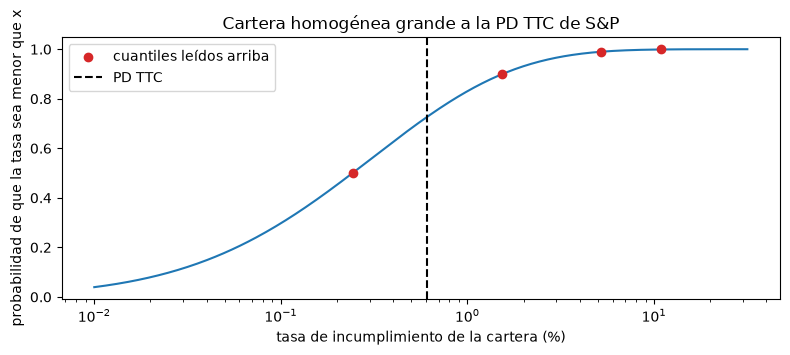

In [4]:
# Draw the distribution function of the portfolio default rate with its quantiles
rates = np.logspace(-4, -0.5, 400)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(100 * rates, vasicek.lhp_cdf(rates, ttc_pd, rho), color="tab:blue")
ax.scatter(100 * quantiles, levels, color="tab:red", zorder=3, label="cuantiles leídos arriba")
ax.axvline(100 * ttc_pd, color="black", linestyle="--", label="PD TTC")
ax.set_xscale("log")
ax.set_xlabel("tasa de incumplimiento de la cartera (%)")
ax.set_ylabel("probabilidad de que la tasa sea menor que x")
ax.set_title("Cartera homogénea grande a la PD TTC de S&P")
ax.legend()
fig.tight_layout()
plt.show()

La curva sube rápido por las tasas bajas y luego se aplana en una cola larga: un año mediano incumple a 0,4 veces la PD, la tasa de la cartera queda bajo su propia PD en el 72% de los años, y el año al 99,9% incumple a unas dieciocho veces la PD. Esa cola, y no el promedio, es lo que cubre el capital del banco. Los puntos rojos no muestran qué tan probable es la cola en la práctica: salen del factor único del modelo y de una correlación tomada de la regulación, de modo que dicen qué tan grande es un mal año si el modelo es correcto. La última cohorte queda en un factor algo menor que cero, un poco peor que el ciclo promedio.

### Paso 2: una exposición por la función IRB

El requerimiento de capital IRB de Basilea III para una exposición no minorista (CRE31.5) es la pérdida en el año al 99,9% menos la pérdida esperada, con un ajuste por vencimiento:

$$K = \left[\mathrm{LGD}\,\Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD}) + \sqrt{R}\,\Phi^{-1}(0{,}999)}{\sqrt{1-R}}\right) - \mathrm{PD}\cdot\mathrm{LGD}\right]\frac{1 + (M - 2{,}5)\,b}{1 - 1{,}5\,b}, \quad b = (0{,}11852 - 0{,}05478 \ln \mathrm{PD})^2$$

La correlación de activos es $R = 0{,}12\,\frac{1 - e^{-50\,\mathrm{PD}}}{1 - e^{-50}} + 0{,}24\left(1 - \frac{1 - e^{-50\,\mathrm{PD}}}{1 - e^{-50}}\right)$ (CRE31.5): baja de 24% para un deudor muy seguro a 12% para uno muy riesgoso. El ponderador de riesgo es $12{,}5\,K$, una fracción de la exposición. El término entre corchetes es el cuantil de la LHP del Paso 1 en $q = 0{,}999$ por la LGD. El `capital_requirement` del motor devuelve un `IRBResult` con cada intermedio. La celda siguiente toma una exposición corporativa con PD 1%, LGD 45% y vencimiento de 2,5 años, y reconstruye $K$ desde el cuantil de la LHP y el ajuste por vencimiento del resultado, para leer lado a lado los dos módulos del motor.

In [5]:
# One corporate exposure through the engine's IRB function, and K rebuilt from the LHP quantile
pd_one, lgd, maturity = 0.01, 0.45, 2.5
result = irb.capital_requirement("corporate", pd_one, lgd, maturity=maturity, regime="basel3")
conditional = float(vasicek.lhp_quantile(0.999, pd_one, result.correlation))
k_rebuilt = lgd * (conditional - pd_one) * result.maturity_adjustment

print(f"correlación de activos {result.correlation:.4f}, PD en el año al 99,9% {conditional:.4f}")
print(f"ajuste por vencimiento {result.maturity_adjustment:.4f}")
print(f"K {result.k:.5f} (reconstruida desde el cuantil de la LHP {k_rebuilt:.5f})")
print(f"ponderador de riesgo {result.risk_weight:.4f}")
print(f"capital por 100 de exposición al 8% {100 * result.risk_weight * 0.08:.3f}")

correlación de activos 0.1928, PD en el año al 99,9% 0.1403
ajuste por vencimiento 1.2598
K 0.07385 (reconstruida desde el cuantil de la LHP 0.07385)
ponderador de riesgo 0.9232
capital por 100 de exposición al 8% 7.385


La exposición tiene una correlación de 0,19 y una PD condicional de 14% en el mal año, catorce veces su propia PD. Quitada la pérdida esperada y aplicado el ajuste por vencimiento, K es 7,4% de la exposición y el ponderador 92%: el banco mantiene unos siete y medio de capital por cada cien prestados. La K reconstruida es igual a la del motor, de modo que los dos módulos coinciden en lo que significa la fórmula. La figura siguiente recorre la PD para mostrar cómo se mueven el ponderador y la correlación.

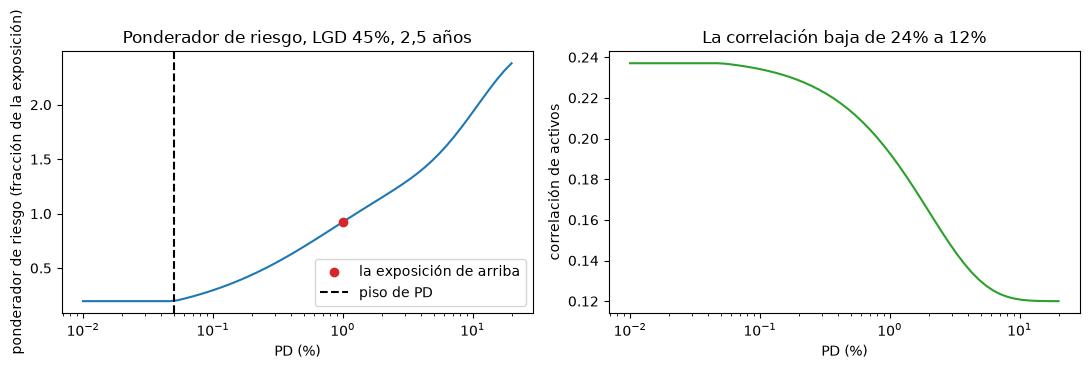

In [6]:
# Sweep the PD: risk weight and asset correlation of the corporate exposure under Basel III
pd_axis = np.logspace(-4, -0.7, 60)
sweep = [irb.capital_requirement("corporate", p, lgd, maturity=maturity, regime="basel3") for p in pd_axis]
floor = irb.REGIMES["basel3"].pd_floor

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(100 * pd_axis, [r.risk_weight for r in sweep], color="tab:blue")
left.scatter(100 * pd_one, result.risk_weight, color="tab:red", zorder=3, label="la exposición de arriba")
left.axvline(100 * floor, color="black", linestyle="--", label="piso de PD")
left.set_xscale("log")
left.set_xlabel("PD (%)")
left.set_ylabel("ponderador de riesgo (fracción de la exposición)")
left.set_title("Ponderador de riesgo, LGD 45%, 2,5 años")
left.legend()
right.plot(100 * pd_axis, [r.correlation for r in sweep], color="tab:green")
right.set_xscale("log")
right.set_xlabel("PD (%)")
right.set_ylabel("correlación de activos")
right.set_title("La correlación baja de 24% a 12%")
fig.tight_layout()
plt.show()

Bajo la línea punteada la curva es plana: una PD menor que el piso se sube al piso antes de aplicar la fórmula. Sobre ella el ponderador crece con la PD pero se aplana, porque la correlación de la derecha baja a medida que el deudor es más riesgoso. Un deudor más riesgoso agrega entonces capital menos que proporcionalmente a su PD. El punto rojo es la exposición de 1% de la celda anterior. Nada en la figura dice que un ponderador mayor sea una peor decisión del banco: la función cobra solo la pérdida inesperada, y la pérdida esperada la cubren las provisiones.

### Paso 3: regímenes, pisos y el factor 1,06

El motor tiene cuatro regímenes (`irb.REGIMES`): Basilea III final, el CRR3 de la UE (Artículo 153), Basilea II como rigió hasta 2022 y los métodos internos del regulador chileno (RAN 21-6). Difieren en dos cosas que este notebook puede ver: el piso de PD (0,05% en Basilea III y CRR3, 0,03% en Basilea II) y el factor de escala 1,06 sobre los activos ponderados por riesgo, que existe en Basilea II (CRE30.4) y ni en Basilea III final ni en el CRR3 Artículo 153. La celda siguiente cotiza la misma exposición corporativa bajo los cuatro regímenes en un barrido de PD, e imprime los ponderadores en tres de ellas. Luego cotiza las clases minoristas del caso C01 bajo dos de los regímenes de su grilla, con las PD de la grilla y una LGD de 50%.

In [7]:
# The same corporate exposure under the four regimes over a PD sweep, and the retail classes of the C01 grid
weights = {}
for regime_id in irb.REGIMES:
    weights[regime_id] = np.array(
        [irb.capital_requirement("corporate", p, lgd, maturity=maturity, regime=regime_id).risk_weight for p in pd_axis]
    )
for at in (5, 25, 55):
    row = " ".join(f"{regime_id} {weights[regime_id][at]:.4f}" for regime_id in irb.REGIMES)
    ratio = weights["basel2"][at] / weights["basel3"][at]
    print(f"PD {pd_axis[at]:.4f}: {row} | basel2 / basel3 {ratio:.3f}")

retail_pds = sorted({point["pd"] for point in holdout["outputs"]["irb"]["parity"]})
retail = {}
for regime_id in ("basel3", "basel2"):
    for label, asset, revolver in (("QRRE revolvente", "qrre", True), ("otro minorista", "other_retail", False)):
        retail[(regime_id, label)] = [
            irb.capital_requirement(asset, p, 0.5, revolver=revolver, regime=regime_id).risk_weight for p in retail_pds
        ]

PD 0.0002: basel3 0.1965 crr3 0.1965 basel2 0.1531 cl_ran21_6 0.1965 | basel2 / basel3 0.779
PD 0.0025: basel3 0.4949 crr3 0.4949 basel2 0.5246 cl_ran21_6 0.4949 | basel2 / basel3 1.060
PD 0.1192: basel3 2.0567 crr3 2.0567 basel2 2.1801 cl_ran21_6 2.0567 | basel2 / basel3 1.060


El panel izquierdo de la figura siguiente es la razón de los ponderadores de Basilea II, CRR3 y RAN 21-6 al de Basilea III a lo largo del barrido de PD. El panel derecho dibuja los ponderadores minoristas en las PD de la grilla. La razón muestra los dos efectos por separado: una caída donde los dos pisos discrepan y una constante donde no.

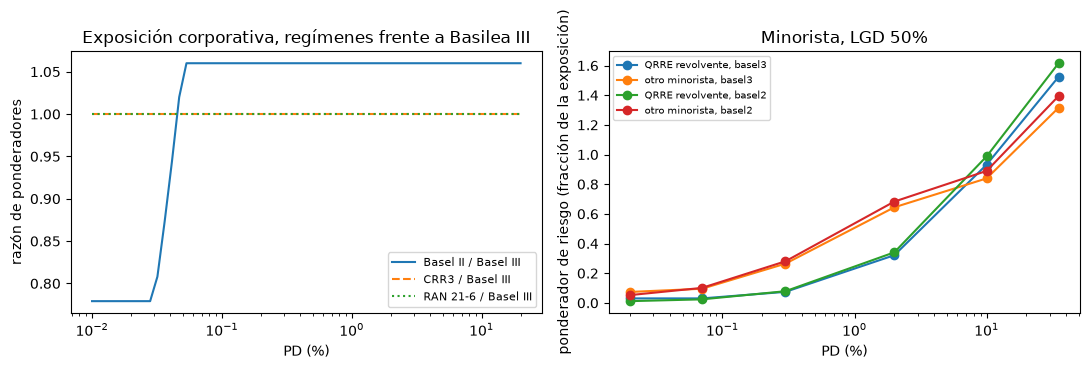

In [8]:
# Draw the regime ratios and the retail weights
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(100 * pd_axis, weights["basel2"] / weights["basel3"], label="Basel II / Basel III")
left.plot(100 * pd_axis, weights["crr3"] / weights["basel3"], label="CRR3 / Basel III", linestyle="--")
left.plot(100 * pd_axis, weights["cl_ran21_6"] / weights["basel3"], label="RAN 21-6 / Basel III", linestyle=":")
left.set_xscale("log")
left.set_xlabel("PD (%)")
left.set_ylabel("razón de ponderadores")
left.set_title("Exposición corporativa, regímenes frente a Basilea III")
left.legend(fontsize=8)
for (regime_id, label), values in retail.items():
    right.plot(100 * np.array(retail_pds), values, marker="o", label=f"{label}, {regime_id}")
right.set_xscale("log")
right.set_xlabel("PD (%)")
right.set_ylabel("ponderador de riesgo (fracción de la exposición)")
right.set_title("Minorista, LGD 50%")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

A la izquierda, Basilea II es exactamente 1,06 veces Basilea III una vez que la PD supera ambos pisos. Bajo el piso de 0,03% de Basilea II la razón es plana en cerca de 0,78, porque Basilea II sube la PD a un piso menor y el ponderador de Basilea III se queda en el suyo; entre ambos pisos sube de un nivel al otro. El CRR3 y el método chileno trazan la línea en 1: para esta exposición corporativa dan el número de Basilea III. A la derecha, los ponderadores minoristas los fijan la clase y la PD: con las PD más bajas otro minorista pesa más en Basilea III, que tiene el piso mayor, y desde la mitad del rango las líneas de Basilea II quedan sobre las de Basilea III por el factor de escala. La figura no dice que los regímenes coincidan en otras clases de activo; muestra solo las filas corporativa y minorista que cotiza el producto.

### Paso 4: de las PD de largo plazo al ponderador de una cartera

El notebook 01 dio a cada grado su PD de largo plazo bajo dos definiciones de incumplimiento: `d2`, la página de incumplimiento de CEREP, y `d4`, su página de transición. La cartera es la mezcla de grados de las 26 cohortes, y su ponderador medio es la suma de los ponderadores de los grados ponderada por la mezcla. Los grados AAA, AA y A tienen PD de largo plazo bajo 0,05%, de modo que el piso de PD obliga ahí y su ponderador es el del piso. La celda siguiente cotiza cada grado bajo ambas definiciones con el motor e informa los grados que subió al piso y los dos ponderadores de la cartera. La diferencia entre ambos ponderadores es el tema del notebook 10.

In [9]:
# Risk weight of every grade under both definitions of default, and the average at the cohort mix
spec = out["irb"]
settings = {"lgd": spec["lgd"], "maturity": spec["maturity"], "regime": spec["regime"]}
mix = np.array([c["size"] for c in out["cohorts"]], dtype=float).sum(axis=0)
mix = mix / mix.sum()
by_grade, portfolio, floored = {}, {}, {}
for definition in ("d2", "d4"):
    rates_by_grade = out["lra"][definition]["rate"]
    results = [irb.capital_requirement(spec["asset_class"], float(p), **settings) for p in rates_by_grade]
    by_grade[definition] = np.array([r.risk_weight for r in results])
    floored[definition] = [grades[i] for i, r in enumerate(results) if r.pd_applied != r.pd_input]
    portfolio[definition] = float(mix @ by_grade[definition])
    print(f"{definition}: ponderador de la cartera {portfolio[definition]:.4f}")
    print(f"{definition}: grados en el piso {floored[definition]}")
print(f"ponderador con d4 sobre ponderador con d2 {portfolio['d4'] / portfolio['d2']:.3f}")

d2: ponderador de la cartera 0.5797
d2: grados en el piso ['AAA', 'AA', 'A']
d4: ponderador de la cartera 0.4745
d4: grados en el piso ['AAA', 'AA', 'A']
ponderador con d4 sobre ponderador con d2 0.819


La figura muestra el ponderador de cada grado bajo las dos definiciones, con los promedios de la cartera como líneas horizontales. Las tres primeras barras son iguales porque están en el piso.

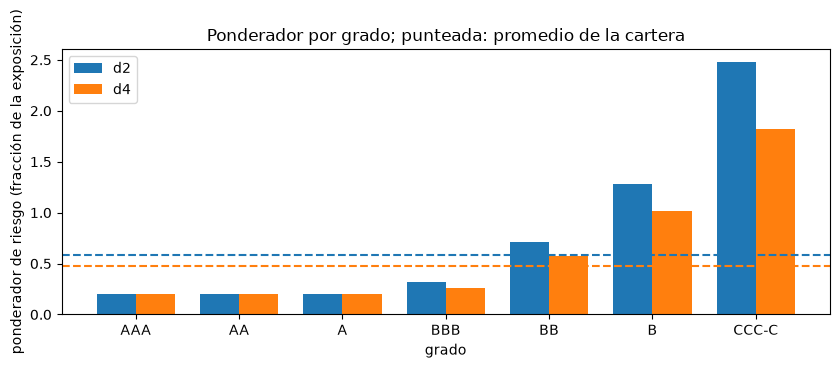

In [10]:
# Draw the risk weight by grade under the two definitions with the portfolio averages
fig, ax = plt.subplots(figsize=(8.5, 3.6))
width = 0.38
for k, definition in enumerate(("d2", "d4")):
    bars = ax.bar(np.arange(7) + (k - 0.5) * width, by_grade[definition], width, label=definition)
    ax.axhline(portfolio[definition], color=bars[0].get_facecolor(), linestyle="--")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_xlabel("grado")
ax.set_ylabel("ponderador de riesgo (fracción de la exposición)")
ax.set_title("Ponderador por grado; punteada: promedio de la cartera")
ax.legend()
fig.tight_layout()
plt.show()

AAA, AA y A pesan lo mismo bajo ambas definiciones, 0,1965, porque sus PD de largo plazo están bajo el piso; la diferencia entre las definiciones viene por completo de BBB hacia abajo, y sobre todo de CCC-C, donde la PD de largo plazo es 26,6% con `d2` y 8,6% con `d4`. Las líneas punteadas son los promedios de la cartera, que dependen también de la mezcla: A, BBB y BB concentran casi toda la exposición, de modo que el gran ponderador de CCC-C pesa poco en el promedio. La figura muestra lo que la definición hace al capital y no cuál definición es la correcta.

### Paso 5: una proyección que deriva hacia una cartera propia

Un modelo de pruebas de estrés suele proyectar una cartera año a año con una matriz de migración $T$, castiga la parte en incumplimiento y la reoriginan con un vector $O$ para mantener el balance constante (Engelmann, 2024):

$$W_t' = W_{t-1}'\,T\,I_w + \bigl(W_{t-1}'\,T\,V_w\bigr)\,O'$$

con $I_w$ la identidad cuya última entrada diagonal es 0 y $V_w$ la columna de incumplimiento. Engelmann muestra que, si el bloque vigente de $T$ es primitivo y nada se origina en incumplimiento, la iteración converge a una única cartera a través del ciclo $W_{\mathrm{ttc}}$ sea cual sea la cartera inicial. La convergencia no es monótona: la PD de la cartera puede subir y bajar en el camino, una recesión o un auge espurios que produce la matriz y no la economía. El `ttc.project` del motor aplica este mapa. La celda siguiente parte de la mezcla de grados de la última cohorte, reorigina con la mezcla de origen observada y proyecta 15 años bajo la matriz agrupada de S&P. También lee las cuatro trayectorias impresas de Engelmann (la matriz del artículo, 50 años) e imprime su inicio, su extremo y su final.

In [11]:
# Project the latest cohort's mix under the pooled S&P matrix, and read Engelmann's four printed paths
pooled = np.array(out["pooled"]["matrix"], dtype=float)
origination = np.array(out["origination"], dtype=float)
latest = np.array(out["cohorts"][-1]["size"], dtype=float)
latest_mix = np.append(latest / latest.sum(), 0.0)
projection = ttc.project(pooled, latest_mix, origination, years=15)
sp_rates = projection["default_rate"]
sp_ttc = projection["ttc"]["default_rate"]
print(f"S&P: año 1 {sp_rates[0]:.4f}, año 15 {sp_rates[-1]:.4f}, TTC {sp_ttc:.4f}")
print(f"S&P: máximo {sp_rates.max():.4f} en el año {sp_rates.argmax() + 1}")

engelmann = published["outputs"]["engelmann"]
for pf in engelmann["portfolios"]:
    path = np.array(pf["pd_path"])
    high, low = f"{path.max():.5f} ({path.argmax()})", f"{path.min():.5f} ({path.argmin()})"
    print(f"{pf['name']:9s} inicio {path[0]:.5f}, máximo {high}, mínimo {low}, final {path[-1]:.5f}")
print(f"TTC PD del artículo: {engelmann['ttc_pd']['printed']}")

S&P: año 1 0.0077, año 15 0.0074, TTC 0.0061
S&P: máximo 0.0080 en el año 4
W_init    inicio 0.01161, máximo 0.01697 (6), mínimo 0.01161 (0), final 0.01236
W_init 2  inicio 0.02724, máximo 0.02724 (0), mínimo 0.00722 (20), final 0.01010
W tilde   inicio 0.01827, máximo 0.02140 (4), mínimo 0.01237 (49), final 0.01237
W hat     inicio 0.01095, máximo 0.01195 (49), mínimo 0.01095 (0), final 0.01195
TTC PD del artículo: 0.01198


La figura dibuja a la izquierda las cuatro trayectorias impresas frente a la PD TTC, y a la derecha la proyección de la cartera de S&P frente a su tasa de incumplimiento TTC.

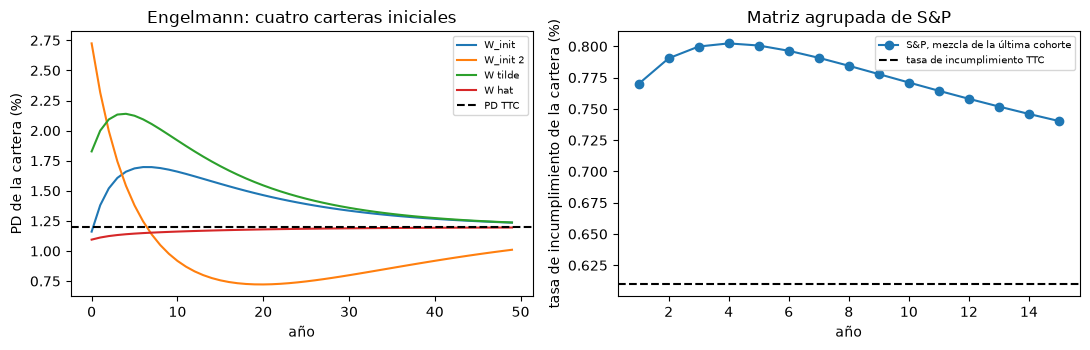

In [12]:
# Draw Engelmann's four printed paths and the S&P projection against their TTC levels
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for pf in engelmann["portfolios"]:
    left.plot(100 * np.array(pf["pd_path"]), label=pf["name"])
left.axhline(100 * engelmann["ttc_pd"]["printed"], color="black", linestyle="--", label="PD TTC")
left.set_xlabel("año")
left.set_ylabel("PD de la cartera (%)")
left.set_title("Engelmann: cuatro carteras iniciales")
left.legend(fontsize=7)
right.plot(range(1, 16), 100 * sp_rates, marker="o", label="S&P, mezcla de la última cohorte")
right.axhline(100 * sp_ttc, color="black", linestyle="--", label="tasa de incumplimiento TTC")
right.set_xlabel("año")
right.set_ylabel("tasa de incumplimiento de la cartera (%)")
right.set_title("Matriz agrupada de S&P")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

A la izquierda, tres de las cuatro carteras iniciales dan un rodeo. Una parte cerca de 1,2%, sube a 1,7% en seis años y luego se asienta cerca de la PD TTC; otra parte en 2,7%, baja hasta 0,7% hacia el año 20 y vuelve a subir. Solo la cuarta se mueve en una dirección. Cada subida y bajada se leería como una recesión o un auge en una prueba de estrés, pero la economía no está en el modelo: la hace la matriz sola. A la derecha, la cartera de S&P parte sobre su tasa TTC, sube un poco más y luego baja lentamente, todavía sobre la tasa TTC tras 15 años. La figura no dice que las pruebas de estrés estén mal, solo que un horizonte más corto que la convergencia confunde la mezcla inicial con el escenario.

## Resultados

**Respuesta:** A la PD TTC de S&P de 0,0061 la cartera homogénea grande incumple a 0,1091 en un año al 99,9%, 17,9 veces su PD, y una exposición corporativa con PD 1%, LGD 45% y vencimiento de 2,5 años lleva una K de 0,07385 y un ponderador de riesgo de 0,9232: 7,385 de capital por cada 100 prestados. El piso de PD iguala los ponderadores de AAA, AA y A, 0,1965, el régimen mueve el ponderador por el factor 1,06 de Basilea II sobre los pisos, y la definición de incumplimiento mueve el ponderador medio de la cartera de 0,5797 con `d2` a 0,4745 con `d4`, una razón de 0,819. Una proyección con la matriz agrupada de S&P no mantiene la PD donde la dejó la economía: la tasa de incumplimiento pasa de 0,0077 a un máximo de 0,0080 en el año 4 y todavía es 0,0074 en el año 15, frente a una tasa TTC de 0,0061.

- **La cola, no el promedio.** La tasa de incumplimiento de la LHP a la PD TTC es 0,0024 en el año mediano, 0,0154 en un año al 90%, 0,0523 en un año al 99% y 0,1091 en un año al 99,9%; la cartera queda bajo su propia PD en el 72% de los años. La correlación a esa PD es 0,2085 y la tasa de la última cohorte, 0,0077, implica un factor de -0,77.
- **Una exposición.** La correlación es 0,1928, la PD en el año al 99,9% es 0,1403, el ajuste por vencimiento 1,2598 y K 0,07385, igual a la K reconstruida desde el cuantil de la LHP. Pasado el piso el ponderador crece con la PD y se aplana cuando la correlación baja de cerca de 24% a 12%.
- **Regímenes.** Con PD de 0,0002, 0,0025 y 0,1192 Basilea III y el CRR3 pesan 0,1965, 0,4949 y 2,0567 y RAN 21-6 da los mismos números; Basilea II pesa 0,1531, 0,5246 y 2,1801, una razón a Basilea III de 0,779 bajo su propio piso y de 1,060 sobre ambos pisos.
- **De las PD a una cartera.** El piso obliga a AAA, AA y A con ambas definiciones. La mezcla de cohortes tiene un ponderador medio de 0,5797 con las PD de la página de incumplimiento y de 0,4745 con las de la página de transición, 0,819 veces el primero, el tema del notebook 10.
- **La deriva.** Trayectorias impresas de Engelmann: W_init parte en 0,01161, sube a 0,01697 en el año 6 y termina en 0,01236; W_init 2 parte en 0,02724, baja a 0,00722 en el año 20 y termina en 0,01010; W tilde parte en 0,01827, sube a 0,02140 en el año 4 y termina en 0,01237; solo W hat es monótona. La PD TTC del artículo es 0,01198.

Lo que este notebook no muestra: el piso agregado de activos ponderados de Basilea III y el enfoque estandarizado (fuera de los casos IRB de este producto), ni cómo la elección de la PD mueve el capital entre enfoques de calibración (notebook 09).

## Resumen

- El ponderador de riesgo IRB es la pérdida en un año al 99,9% de una cartera homogénea grande menos la pérdida esperada, con un ajuste por vencimiento; los módulos IRB y Vasicek del motor coinciden en ello.
- El ponderador crece con la PD pero se aplana, porque la correlación de activos baja de 24% a 12%; bajo el piso es plano.
- Los regímenes difieren por el piso de PD y por el factor 1,06 de Basilea II; Basilea III final y el CRR3 dan el mismo ponderador en una exposición corporativa.
- Una PD de largo plazo bajo el piso pesa como el piso, y la definición de incumplimiento mueve el ponderador de una cartera en cerca de una quinta parte.
- Una proyección con una matriz de migración deriva hacia una cartera propia y su PD puede subir y bajar en el camino: un ciclo espurio.

**Qué probar después.** Cambia la LGD del Paso 2 a 0,40 y el vencimiento a 1 y 5 años, y lee cómo se mueve K; luego lee el notebook 08.

## Referencias

- BCBS, Basel Framework, CRE31 (enfoque IRB: funciones de ponderación) y CRE32 (componentes de riesgo: LGD, vencimiento, piso de PD), y CRE30.4 para el factor de escala de Basilea II. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), doi 10.1016/S1042-9573(03)00040-8.
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892, ecuaciones 9 y 10, Teorema 1 y sección 4.
- Reglamento (UE) 2024/1623 (CRR3), Artículo 153, para el régimen de la UE.